# Module 4 — Evaluating Retrieval

Part of the RAG Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

**Where this module starts**
- RAG (retrieval-augmented generation) answers a question in two steps:
  1. A search program finds the few texts in a collection that match the question.
  2. A language model, the kind of program behind chat assistants, reads those texts and writes the answer.
- A RAG system is built from five parts:
  1. Chunk: split each document into short pieces
  2. Embed: turn each piece into an embedding, a list of numbers that an embedding model makes from a text, so that texts with similar meaning get similar embeddings
  3. Store: keep every piece's embedding in one table
  4. **Retrieve**: for each question, return the pieces that match it best
  5. Generate: the language model reads those pieces and writes the answer
- Part 4, retrieve, can search three ways. Each way ranks every piece, from 1 (best) down, and returns the top few:
  1. Meaning search ranks the pieces by how close their embeddings are to the question's embedding.
  2. Keyword search ranks the pieces by the words they share with the question, with words that few pieces in the collection contain counting more than common ones. Its score is called BM25 (Best Matching 25).
  3. Hybrid search combines the two rankings into one.
- Each way can find pieces the others miss: meaning search can miss a piece that repeats the question's exact words, such as a name, because an embedding follows the topic more than the exact words, and keyword search can miss one that says the same thing in other words. So which way is better depends on the questions, and only a grade over many questions can say.

**This module's point:** it builds no new part. It grades part 4, retrieve: over every question of a test set whose supporting pieces are known, how many of those pieces does each way of searching return, and how high does it rank them? The grades decide which way the live search, the one that will answer real users' questions, should use.<br>
<u>Note</u>: in this module every piece is one sentence, so part 1, chunk, is skipped. Part 2, embed, uses an existing embedding model, nomic-embed-text. Part 3, store, keeps every sentence's embedding in one table, as in any RAG system. Part 5, generate, is not run in this module: the grades judge the sentences the searches return, not answers.

**What this module measures**

The test set is a public dataset called MultiHop-RAG. It has questions about news articles, and for each question it lists the sentences in the articles that support the answer. A listed sentence is found when the search returns it, and the grades give credit for each listed sentence found.

Two grades, each calculated for every question and then averaged over the questions, for each way of searching:
1. Recall@4 ("recall at 4"): the share of a question's listed sentences that the search returns in its top 4.
2. MRR@4 (mean reciprocal rank at 4): 1 / (rank of the highest-ranked listed sentence), or 0 when none is in the top 4.

<u>Note</u>: both are written grade@k, where k is the number of sentences the search returns: 4 here.

The module runs six steps:
1. Search every question the three ways (meaning, keyword, hybrid), and keep the rank each way gave each listed sentence.
2. Recall@4 of each way of searching.
3. MRR@4 of each way of searching.
4. Are the gaps between the ways larger than another set of test questions could produce by chance?
5. Recall when the search returns k sentences (k > 4, k < 4).
6. The three kinds of questions (comparison, inference, temporal).

**Two tags in this module**
- **[in real life]** marks a step an analyst runs to grade a search before it goes live. A live user's question comes with no list of supporting sentences, so the analyst grades the search on test questions that do have one, such as this dataset's questions.
- **[only in this module]** marks a choice that makes this module simpler than a real search.

**What this module produces**
1. Recall@4 and MRR@4 of each way of searching, over every question that lists sentences.
2. A test of which gaps between the ways are larger than chance.
3. Recall for every top-k size from 1 to 20, in a chart.
4. The two grades again, within each kind of question separately.

## From the curriculum

> ## <u>Module 4 — Evaluating Retrieval</u>
>
> **Concepts**
> - What "found the right material" means: the retrieved chunks contain the
>   labelled supporting sentences
> - Recall@k: the share of supporting sentences found in the top k
> - MRR@k (mean reciprocal rank at k): how high the first right chunk ranks
> - Comparing search methods on the same questions
>
> **Worked example:** keyword, meaning and hybrid search graded on the same
> sample of questions.

## Lesson

In the curriculum above, a chunk is a piece, and in this module every piece is one sentence. The labelled supporting sentences are the listed sentences, and the first right chunk is the first listed sentence, defined below.

### What "found" means

A search ranks every sentence in the collection, from 1 (best) down, and returns the top k, where k is a number chosen in advance. A listed sentence is **found** when its rank is k or better.

A returned sentence that is not listed counts as not found, even when it is on the question's topic. The grades count only the listed sentences.

### Recall@k

**formula**:

Recall@k of a question = (listed sentences ranked k or better) / (sentences listed for the question)

In words:
- Recall@k is 1 when the top k holds every listed sentence, and 0 when it holds none.
- The unlisted sentences in the top k do not enter the formula.

A search's recall@k is the average of recall@k over all the questions. Each question counts once, whether it lists few sentences or many.

A hand example with k = 4 and two questions, ranks chosen for easy arithmetic:
- Question A lists 3 sentences, ranked 2, 9 and 3. Recall@4 of question A = 2 / 3 = 0.667, because ranks 2 and 3 are 4 or better.
- Question B lists 2 sentences, ranked 7 and 12. Recall@4 of question B = 0 / 2 = 0.
- Recall@4 of the search = (0.667 + 0) / 2 = 0.333

### MRR@k

Recall@k says how many listed sentences are in the top k, but not where: a listed sentence at rank 1 and one at rank 4 count the same.

A question's **first listed sentence** is the listed sentence the search ranks highest, whatever its place in the dataset's list.

**formula**:

MRR@k of a question = 1 / (rank of the question's first listed sentence), when that rank is k or better, and 0 otherwise

MRR@k of a search = average of MRR@k over all the questions

In words:
- "Reciprocal" means 1 divided by the number. The first listed sentence at rank 1 gives 1, at rank 2 gives 0.5, at rank 4 gives 0.25.
- The ranks of the other listed sentences do not change MRR@k.

The same hand example:
- Question A's first listed sentence is at rank 2. MRR@4 of question A = 1 / 2 = 0.5
- Question B's first listed sentence is at rank 7, below 4. MRR@4 of question B = 0
- MRR@4 of the search = (0.5 + 0) / 2 = 0.25

Why both grades: in this dataset a question's answer combines facts from several sentences, so the language model needs as many of the listed sentences as possible: recall@k counts them. MRR@k shows how high a listed sentence sits: a search with a high MRR@k still returns a listed sentence when k is made smaller, so that the language model has fewer sentences to read.

### Is a gap between two searches real?

The questions graded here are one set of test questions. Another set of questions written the same way would give somewhat different grades. A gap between two searches is real when it is larger than the change another set of questions could make.

Both searches are graded on the same questions, so the comparison is made question by question. Some questions are hard for every search, and some are easy for every search. A question's difficulty raises or lowers both searches' grades on that question together, so the difference on that question keeps mostly the gap between the two searches.

- Difference on a question = (search A's grade on the question) − (search B's grade on the question)
- Mean difference = the average of the differences over all the questions, which equals (search A's average grade) − (search B's average grade)

**formula**:

Standard error of the mean difference = (standard deviation of the differences) / √(number of questions)

95% interval = mean difference − (1.96 × standard error) to mean difference + (1.96 × standard error)

In words:
- The standard deviation of the differences says how far the differences on single questions typically are from their mean.
- The differences vary less from question to question than the grades themselves, because each question's difficulty is in both searches' grades. So the standard deviation of the differences, and the interval, are smaller than when the two averages are compared as if they came from separate questions.
- The standard error says how far the mean difference would typically move from one set of test questions to another of the same size. More questions give a smaller standard error.
- 1.96 is the standard value for a 95% interval: over many sets of test questions, intervals made this way hold the true gap, the gap over all possible questions written the same way, 95% of the time.
- The pass rule, the standard one: the gap is real when 0 is outside the interval. When 0 is inside, the data cannot tell the two searches apart.

<u>Note</u>: which one goes into an interval?
- Standard deviation: when the interval is about single values, such as one question's difference.
- Standard error: when the interval is about a number calculated from a sample, such as an average grade or the mean difference, because that number moves less from sample to sample than single values do.

A hand example, numbers chosen for easy arithmetic: a mean difference of 0.05, a standard deviation of 0.25, and 2,500 questions.
- Standard error = 0.25 / √2,500 = 0.25 / 50 = 0.005
- 95% interval = 0.05 − (1.96 × 0.005) to 0.05 + (1.96 × 0.005) = 0.0402 to 0.0598
- 0 is outside the interval, so search A is better than search B by more than chance.

The code below loads the tools and checks the three functions used in this module, the two grades and the interval, against the hand examples above: each printed number should equal its hand calculation. `common` is this playbook's shared helper file: it loads the data, calls the models, and prints tables.

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common
from common import show

TOP_K = 4


def recall_at(ranks, k=TOP_K):
    # ranks: the ranks of one question's listed sentences
    return sum(r <= k for r in ranks) / len(ranks)


def reciprocal_rank_at(ranks, k=TOP_K):
    first = min(ranks)
    return 1 / first if first <= k else 0.0


def interval(differences):
    d = np.asarray(differences, dtype=float)
    standard_error = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean() - 1.96 * standard_error, d.mean() + 1.96 * standard_error


print(f"Recall@4 of question A (ranks 2, 9, 3) = {recall_at([2, 9, 3]):.3f}")
print(f"Recall@4 of question B (ranks 7, 12) = {recall_at([7, 12]):.3f}")
print(f"Recall@4 of the search = {np.mean([recall_at([2, 9, 3]), recall_at([7, 12])]):.3f}")
print()
print(f"MRR@4 of question A = {reciprocal_rank_at([2, 9, 3]):.2f}")
print(f"MRR@4 of question B = {reciprocal_rank_at([7, 12]):.2f}")
print(f"MRR@4 of the search = {np.mean([reciprocal_rank_at([2, 9, 3]), reciprocal_rank_at([7, 12])]):.2f}")
print()
# 2,500 differences, half 0.30 and half −0.20: their mean is 0.05 and their standard deviation about 0.25
low, high = interval([0.30] * 1250 + [-0.20] * 1250)
print(f"95% interval (mean difference 0.05, standard deviation 0.25, 2,500 questions) = {low:.4f} to {high:.4f}")

Recall@4 of question A (ranks 2, 9, 3) = 0.667
Recall@4 of question B (ranks 7, 12) = 0.000
Recall@4 of the search = 0.333

MRR@4 of question A = 0.50
MRR@4 of question B = 0.00
MRR@4 of the search = 0.25

95% interval (mean difference 0.05, standard deviation 0.25, 2,500 questions) = 0.0402 to 0.0598


## The data: the questions and the sentences they list

The dataset is MultiHop-RAG (Tang and Yang, 2024):
- 609 news articles, published between September and December 2023
- 2,556 questions about those articles. For 2,255 of them, the dataset lists 2 to 4 sentences from the articles that support the answer. The other 301 ask something no article answers, and list no sentences.

**[only in this module]** The collection searched is every sentence the dataset lists, for any question, each unique sentence stored once. In real life, the collection would be every sentence of all 609 articles, most of which no question lists.

In [2]:
questions = common.load_questions()
print(f"Articles = {len(common.load_corpus()):,}")
print(f"Questions = {len(questions):,}")
print(f"Questions with listed sentences = {questions['evidence_list'].str.len().gt(0).sum():,}")
print(f"Questions with no listed sentences, left out = {questions['evidence_list'].str.len().eq(0).sum():,}")
print()

rows = [(q, e["fact"]) for q, listed in questions["evidence_list"].items() for e in listed]
listed = pd.DataFrame(rows, columns=["question", "sentence"])
sentences = listed.drop_duplicates("sentence").reset_index(drop=True)
row_of = {s: i for i, s in enumerate(sentences["sentence"])}

print(f"Sentences listed, over all questions = {len(listed):,}")
print(f"Unique sentences in the collection = {len(sentences):,}")
print(f"Questions each unique sentence is listed for, on average = {len(listed):,} / {len(sentences):,} = {len(listed) / len(sentences):.1f}")
print()

per_question = listed.groupby("question").size().value_counts().sort_index()
table = pd.DataFrame({"sentences listed": [str(n) for n in per_question.index] + ["total"],
                      "questions": [f"{v:,}" for v in per_question] + [f"{per_question.sum():,}"],
                      "share": [f"{v / per_question.sum():.1%}" for v in per_question] + ["100%"]})
print("Questions with listed sentences, by number of sentences listed:")
print()
show(table)

Articles = 609
Questions = 2,556
Questions with listed sentences = 2,255
Questions with no listed sentences, left out = 301

Sentences listed, over all questions = 6,084
Unique sentences in the collection = 981
Questions each unique sentence is listed for, on average = 6,084 / 981 = 6.2

Questions with listed sentences, by number of sentences listed:

sentences listed  questions  share
2                     1,079  47.8%
3                       778  34.5%
4                       398  17.6%
total                 2,255   100%


Four limits of the grades, before any number:
1. The grades are higher than a real search would get. The collection holds only listed sentences, so a search has fewer wrong sentences to rank above the right ones than in all the articles' sentences. The order of the three ways could change too, because the many added unlisted sentences may push down one way's listed sentences more than another's.
2. The 301 questions with no listed sentences are left out. Their recall@4 would divide by 0 listed sentences.
3. The dataset's list may miss sentences that also support an answer. A search that returns such a sentence is graded as if it returned a wrong one, so the grades can understate every search.
4. The questions are not fully independent of each other: the dataset lists each unique sentence for 6.2 questions on average, because several questions ask about the same facts. A search that ranks a shared sentence high for one question tends to rank it high for the others, so questions that share listed sentences can get similar grades, so 2,255 such questions carry less information than 2,255 unrelated ones would, and the 95% intervals in Step 4 are somewhat narrower than they should be.

Each search returns its top 4 sentences: k = 4, because no question lists more than 4 sentences, so 4 leaves room for every listed sentence of any question.

## Step 1 of 6: search every question the three ways

**What does each way of searching return for each test question?** The grades in the later steps are calculated from one thing only: the rank each way of searching gave each listed sentence. This step finds those ranks.

**[in real life]** Every test question is searched the three ways, exactly as a live search would search it, and the rank of each listed sentence is kept:
1. Meaning search: every sentence is turned into an embedding once, with nomic-embed-text, and each question is turned into an embedding. The sentences are ranked by cosine similarity with the question's embedding, from highest down: a number from −1 to 1, higher when the two texts' meanings are closer.
2. Keyword search: the sentences are ranked by their BM25 score for the question, from highest down: higher when the sentence shares more of the question's words, especially rare ones.
3. Hybrid search: the sentences are ranked by their hybrid score, 1 / (60 + rank in meaning search) + 1 / (60 + rank in keyword search), from highest down: higher when a sentence ranks high in both searches.

The embedding model expects a short label in front of every text, as its makers trained it: "search_document: " in front of a sentence to be searched, and "search_query: " in front of a question.

In [3]:
# Meaning search: one embedding per sentence and per question, then cosine similarity.
store = common.embed(sentences["sentence"].tolist(), prefix="search_document: ")
graded = sorted(listed["question"].unique())
question_embeddings = common.embed([questions["query"][q] for q in graded], prefix="search_query: ")
unit = lambda m: m / np.linalg.norm(m, axis=1, keepdims=True)
cosine = unit(question_embeddings) @ unit(store).T          # one row per question, one column per sentence

# Keyword search: BM25 with its standard settings.
K1, B, RRF = 1.2, 0.75, 60
words_of = lambda text: re.findall(r"[a-z0-9]+", text.lower())
sentence_words = [words_of(s) for s in sentences["sentence"]]
N = len(sentences)
words_per_sentence = np.array([len(w) for w in sentence_words])
average_words = words_per_sentence.mean()
sentences_with = Counter(w for ws in sentence_words for w in set(ws))
column_of = {w: j for j, w in enumerate(sentences_with)}
times_in = np.zeros((N, len(column_of)))                    # times each word is in each sentence
for i, ws in enumerate(sentence_words):
    for w, c in Counter(ws).items():
        times_in[i, column_of[w]] = c


def keyword_scores(question):
    total = np.zeros(N)
    for w in dict.fromkeys(words_of(question)):
        if w not in column_of:
            continue
        rarity_weight = np.log(1 + (N - sentences_with[w] + 0.5) / (sentences_with[w] + 0.5))
        t = times_in[:, column_of[w]]
        total += rarity_weight * (t * (K1 + 1)) / (t + K1 * (1 - B + B * words_per_sentence / average_words))
    return total


def ranks_of(scores):
    # Rank 1 = highest score. Ties (sentences with the same score) keep the collection's order.
    order = np.argsort(-scores, kind="stable")
    ranks = np.empty(len(scores), dtype=int)
    ranks[order] = np.arange(1, len(scores) + 1)
    return ranks


KIND = {"comparison_query": "comparison", "inference_query": "inference", "temporal_query": "temporal"}
SEARCHES = ["meaning", "keyword", "hybrid"]
results = []
for j, q in enumerate(graded):
    meaning = ranks_of(cosine[j])
    keyword = ranks_of(keyword_scores(questions["query"][q]))
    hybrid = ranks_of(1 / (RRF + meaning) + 1 / (RRF + keyword))
    gold = [row_of[s] for s in dict.fromkeys(listed.loc[listed["question"] == q, "sentence"])]
    for name, ranks in zip(SEARCHES, [meaning, keyword, hybrid]):
        results.append({"question": q, "kind": KIND[questions["question_type"][q]], "search": name,
                        "listed": len(gold), "ranks": [int(ranks[i]) for i in gold]})
results = pd.DataFrame(results)

print(f"Questions searched = {len(graded):,}")
print(f"Searches run = {len(graded):,} questions × 3 ways = {len(results):,}")

Questions searched = 2,255
Searches run = 2,255 questions × 3 ways = 6,765


For every question, Step 1 saves one thing: the rank each way of searching gave each of the question's listed sentences, out of all 981 sentences. Steps 2 to 6 calculate every grade from these saved ranks alone. The table below shows the saved ranks for one question. It lists 2 sentences, L1 and L2, and was chosen because the three ways rank them differently:

In [4]:
EXAMPLE = 1629
print(f"Question: {questions['query'][EXAMPLE]}")
print()
for k, s in enumerate(dict.fromkeys(listed.loc[listed["question"] == EXAMPLE, "sentence"]), start=1):
    print(f"  L{k}: {s}")
print()
example = results[results["question"] == EXAMPLE]
table = pd.DataFrame({"search": example["search"].values,
                      **{f"rank of L{k + 1}": [r[k] for r in example["ranks"]] for k in range(2)}})
show(table)

Question: Did Polygon report on the Bluetooth connectivity of the Microsoft Xbox controller before Engadget discussed the Bluetooth functionality improvements in the Steam Deck OLED?

  L1: The device uses Bluetooth 5.3 and adds a dedicated antenna, which should improve functionality when using Wi-Fi and Bluetooth at the same time.
  L2: So, whether you have a phone or tablet, this controller can easily connect via Bluetooth.

search   rank of L1  rank of L2
meaning           5           1
keyword           2           3
hybrid            4           1


Hybrid search ranks L1 4th, though meaning search ranks it 5th and keyword search 2nd.
- L1's hybrid score = 1 / (60 + 5) + 1 / (60 + 2) = 0.0154 + 0.0161 = 0.0315
- Three sentences have a higher hybrid score than L1's 0.0315: L2, at rank 1, and two unlisted sentences.

## Step 2 of 6: recall@4 of each way of searching

**Which way of searching returns the most listed sentences in its top 4?**

**[in real life]** Each question's recall@4 is calculated from the ranks kept in Step 1, for each way of searching, and averaged over the questions.

First the example question from Step 1, by hand:

In [5]:
for _, row in example.iterrows():
    found = sum(r <= TOP_K for r in row["ranks"])
    print(f"Recall@4 of the example question, {row['search']} search, ranks {row['ranks'][0]} and {row['ranks'][1]}"
          f" = {found} / {row['listed']} = {recall_at(row['ranks']):.2f}")

Recall@4 of the example question, meaning search, ranks 5 and 1 = 1 / 2 = 0.50
Recall@4 of the example question, keyword search, ranks 2 and 3 = 2 / 2 = 1.00
Recall@4 of the example question, hybrid search, ranks 4 and 1 = 2 / 2 = 1.00


Now every question. A question's recall@4 can take only a few values, such as 1 of 2 or 2 of 3 listed sentences found, so the table below counts the questions at each value. Each way's recall@4 is then the average: each value times its number of questions, summed, divided by the number of questions.

In [6]:
results["recall@4"] = results["ranks"].map(recall_at)
counts = results.pivot_table(index="recall@4", columns="search", values="question", aggfunc="count", fill_value=0)[SEARCHES]
found = results["ranks"].map(lambda ranks: sum(r <= TOP_K for r in ranks))
pairs = (results.assign(found=found)
         .pivot_table(index=["listed", "found"], columns="search", values="question", aggfunc="count", fill_value=0)[SEARCHES]
         .reset_index())
table = pd.DataFrame({"listed sentences found": [f"{f} of {n}" for n, f in zip(pairs["listed"], pairs["found"])],
                      "recall@4 of a question": [f"{f / n:.3f}" for n, f in zip(pairs["listed"], pairs["found"])]})
for s in SEARCHES:
    table[f"questions: {s}"] = pairs[s].map(lambda v: f"{v:,}")
table.loc[len(table)] = ["total", ""] + [f"{pairs[s].sum():,}" for s in SEARCHES]
print("Questions at each value of recall@4:")
print()
show(table)
print()
for s in SEARCHES:
    total = (counts[s] * counts.index).sum()
    print(f"Recall@4 of {s} search = sum of (recall@4 × questions at that value) / all questions"
          f" = {total:,.1f} / {counts[s].sum():,} = {total / counts[s].sum():.3f}")

Questions at each value of recall@4:

listed sentences found  recall@4 of a question  questions: meaning  questions: keyword  questions: hybrid
0 of 2                                   0.000                  74                 129                 90
1 of 2                                   0.500                 457                 393                359
2 of 2                                   1.000                 548                 557                630
0 of 3                                   0.000                  76                 104                 57
1 of 3                                   0.333                 316                 264                276
2 of 3                                   0.667                 314                 304                318
3 of 3                                   1.000                  72                 106                127
0 of 4                                   0.000                  31                  28                 12
1 of 4  

**Observation:** hybrid search has the highest recall@4, 0.644. Keyword search, 0.595, and meaning search, 0.592, are 0.003 apart.

**Observation:** hybrid search found every listed sentence for the most questions, 776, and none for the fewest, 159.

**Observation:** keyword search found 0 of the listed sentences for more questions than meaning search, 261 against 181, but also found every listed sentence for more questions than meaning search, 673 against 625. Keyword search gets recall@4 of 0 or 1 more often than meaning search, 934 against 806. Their average recall@4 is about the same: 0.595 and 0.592. So two searches with the same average recall@4 can spread their questions differently.

**Conclusion:** hybrid search returns the most listed sentences in its top 4, and keyword search and meaning search return about the same number on average.

## Step 3 of 6: MRR@4 of each way of searching

**Which way of searching ranks a listed sentence highest?**

**[in real life]** Each question's MRR@4 is calculated from the ranks kept in Step 1, for each way of searching, and averaged over the questions.

First the example question from Step 1, by hand:

In [7]:
for _, row in example.iterrows():
    first = min(row["ranks"])
    calc = f"1 / {first} = {1 / first:.2f}" if first <= TOP_K else "0, because it is below 4"
    print(f"MRR@4 of the example question, {row['search']} search, ranks {row['ranks'][0]} and {row['ranks'][1]} = {calc}")

MRR@4 of the example question, meaning search, ranks 5 and 1 = 1 / 1 = 1.00
MRR@4 of the example question, keyword search, ranks 2 and 3 = 1 / 2 = 0.50
MRR@4 of the example question, hybrid search, ranks 4 and 1 = 1 / 1 = 1.00


Now every question. A question's MRR@4 depends only on where its first listed sentence is, so the table below counts the questions by that rank. Each way's MRR@4 is then the average: each MRR@4 times its number of questions, summed, divided by the number of questions.

In [8]:
results["first listed"] = results["ranks"].map(min)
results["MRR@4"] = results["ranks"].map(reciprocal_rank_at)
place = results["first listed"].map(lambda r: str(r) if r <= TOP_K else "0")
counts = pd.crosstab(place, results["search"])[SEARCHES].reindex(["0", "1", "2", "3", "4"])
weight = {"0": 0, "1": 1, "2": 1 / 2, "3": 1 / 3, "4": 1 / 4}
table = counts.reset_index()
table.columns = ["rank of the first listed sentence"] + [f"questions: {s}" for s in SEARCHES]
table.insert(1, "MRR@4", [f"{weight[p]:.3f}" for p in counts.index])
for s in SEARCHES:
    table[f"questions: {s}"] = table[f"questions: {s}"].map(lambda v: f"{v:,}")
table.loc[len(table)] = ["total", ""] + [f"{counts[s].sum():,}" for s in SEARCHES]
print("Questions by the rank of their first listed sentence:")
print()
show(table)
print()
for s in SEARCHES:
    total = sum(weight[p] * counts.loc[p, s] for p in counts.index)
    print(f"MRR@4 of {s} search = sum of (MRR@4 × questions at that rank) / all questions"
          f" = {total:,.1f} / {counts[s].sum():,} = {total / counts[s].sum():.3f}")

Questions by the rank of their first listed sentence:

rank of the first listed sentence  MRR@4  questions: meaning  questions: keyword  questions: hybrid
0                                  0.000                 181                 261                159
1                                  1.000               1,408               1,650              1,645
2                                  0.500                 447                 201                271
3                                  0.333                 158                  83                125
4                                  0.250                  61                  60                 55
total                                                  2,255               2,255              2,255

MRR@4 of meaning search = sum of (MRR@4 × questions at that rank) / all questions = 1,699.4 / 2,255 = 0.754
MRR@4 of keyword search = sum of (MRR@4 × questions at that rank) / all questions = 1,793.2 / 2,255 = 0.795
MRR@4 of hybrid search = sum

The "0" counts equal Step 2's counts of questions with recall@4 of 0, by design: a question whose first listed sentence is below 4 has no listed sentence in the top 4.

**Observation:** hybrid search has the highest MRR@4, 0.814, then keyword search, 0.795, then meaning search, 0.754.

**Observation:** keyword search put a listed sentence at rank 1 for more questions than meaning search, 1,650 against 1,408. Meaning search more often put its first listed sentence at rank 2, 447 questions against 201. Keyword search's sum of the questions' MRR@4 values, the part of MRR@4 above the division line, is above meaning search's by 1,793.2 − 1,699.4 = 93.8:
- Rank 1 adds (1,650 − 1,408) × 1 = 242 for keyword search.
- Ranks 2, 3 and 4 take back ((447 − 201) × 0.5) + ((158 − 83) × 1/3) + ((61 − 60) × 0.25) = 123 + 25 + 0.25 = 148.25.
- 242 − 148.25 = 93.75, the 93.8 above before rounding. So keyword search's MRR@4 is higher, although its recall@4 is about the same as meaning search's.

**Hypothesis:** a sentence that repeats the question's rarest words, such as a name, gets a BM25 score far above the other sentences, so keyword search ranks it first. Meaning search gives many sentences on the question's topic similar cosine similarities, so the listed one lands at rank 2 or 3 more often.

**Conclusion:** hybrid search ranks a listed sentence highest, and keyword search ranks it higher than meaning search, although the two find about the same number of listed sentences.

## Step 4 of 6: are the gaps between the ways larger than chance?

**Are the gaps in Steps 2 and 3 real, or could another set of test questions reverse them?** Each pair of ways is compared question by question, as in the lesson, and a gap is real when 0 is outside its 95% interval.

**[in real life]** For each pair of ways and each grade, the difference on every question is taken, and the 95% interval of the mean difference is calculated.

First one pair of ways, hybrid search minus keyword search, on recall@4, step by step over all the questions:

In [9]:
grade_of = {g: results.pivot(index="question", columns="search", values=g) for g in ["recall@4", "MRR@4"]}


def compare(a, b, grade):
    d = grade_of[grade][a] - grade_of[grade][b]
    standard_error = d.std(ddof=1) / np.sqrt(len(d))
    return d, standard_error


def doubled(d, se):
    low, high = d.mean() - 2 * 1.96 * se, d.mean() + 2 * 1.96 * se
    return {"interval, half-width doubled": f"{minus(low, 4)} to {minus(high, 4)}",
            "0 inside, doubled?": "yes" if low <= 0 <= high else "no"}


def minus(v, decimals):
    return f"{v:.{decimals}f}".replace("-", "−")


d, se = compare("hybrid", "keyword", "recall@4")
low, high = interval(d)
print(f"Questions = {len(d):,}")
print(f"Mean difference (hybrid recall@4 − keyword recall@4) = {minus(d.mean(), 4)}")
squares = ((d - d.mean()) ** 2).sum()
print(f"Standard deviation of the differences = √(sum of (difference − mean difference)² / (questions − 1))"
      f" = √({squares:,.2f} / {len(d) - 1:,}) = {d.std(ddof=1):.4f}")
print(f"Standard error = standard deviation of the differences / √questions = {d.std(ddof=1):.4f} / √{len(d):,} = {se:.4f}")
print(f"95% interval = {minus(d.mean(), 4)} − (1.96 × {se:.4f}) to {minus(d.mean(), 4)} + (1.96 × {se:.4f})"
      f" = {minus(low, 4)} to {minus(high, 4)}")

Questions = 2,255
Mean difference (hybrid recall@4 − keyword recall@4) = 0.0495
Standard deviation of the differences = √(sum of (difference − mean difference)² / (questions − 1)) = √(107.92 / 2,254) = 0.2188
Standard error = standard deviation of the differences / √questions = 0.2188 / √2,255 = 0.0046
95% interval = 0.0495 − (1.96 × 0.0046) to 0.0495 + (1.96 × 0.0046) = 0.0405 to 0.0585


Now every pair and both grades. Each row is calculated the same way as above.

The questions share listed sentences (limit 4 in the data section), so the intervals are somewhat too narrow, and how much too narrow is not measured here. As a test, the last two columns compensate by doubling each interval's half-width, 1.96 × standard error, with the factor 2 chosen for illustration: interval, half-width doubled = mean difference − (2 × 1.96 × standard error) to mean difference + (2 × 1.96 × standard error).

In [10]:
rows = []
for grade in ["recall@4", "MRR@4"]:
    for a, b in [("hybrid", "keyword"), ("hybrid", "meaning"), ("keyword", "meaning")]:
        d, se = compare(a, b, grade)
        low, high = interval(d)
        rows.append({"grade": "recall@4" if grade == "recall@4" else "MRR@4", "ways compared": f"{a} − {b}",
                     "mean difference": minus(d.mean(), 4), "standard deviation": f"{d.std(ddof=1):.4f}",
                     "standard error": f"{se:.4f}", "95% interval": f"{minus(low, 4)} to {minus(high, 4)}",
                     "0 inside?": "yes" if low <= 0 <= high else "no", **doubled(d, se)})
print(f"Gaps between the ways, {len(d):,} questions:")
print()
show(pd.DataFrame(rows))

Gaps between the ways, 2,255 questions:

grade     ways compared      mean difference  standard deviation  standard error  95% interval       0 inside?  interval, half-width doubled  0 inside, doubled?
recall@4  hybrid − keyword            0.0495              0.2188          0.0046  0.0405 to 0.0585   no         0.0314 to 0.0675              no
recall@4  hybrid − meaning            0.0521              0.2555          0.0054  0.0416 to 0.0627   no         0.0311 to 0.0732              no
recall@4  keyword − meaning           0.0027              0.3226          0.0068  −0.0107 to 0.0160  yes        −0.0240 to 0.0293             yes
MRR@4     hybrid − keyword            0.0190              0.2530          0.0053  0.0085 to 0.0294   no         −0.0019 to 0.0398             yes
MRR@4     hybrid − meaning            0.0605              0.2890          0.0061  0.0486 to 0.0725   no         0.0367 to 0.0844              no
MRR@4     keyword − meaning           0.0416              0.3881       

**Observation:** hybrid search's lead over each of the other two ways is real on both grades: 0 is outside all four intervals.

**Observation:** keyword search minus meaning search on recall@4 has 0 inside its interval, so the data cannot tell the two apart on how many listed sentences they find. On MRR@4, keyword search's lead over meaning search is real.

**Observation:** with the half-widths doubled, every real gap stays real except hybrid search minus keyword search on MRR@4, whose doubled interval holds 0. That gap could turn out not to be real.

**Conclusion:** hybrid search finds more listed sentences than both other ways, even with doubled intervals, and ranks the first one higher than meaning search, while its higher MRR@4 than keyword search's is real only by the standard rule. Keyword search and meaning search find about as many listed sentences, with keyword search ranking the first one higher.

## Step 5 of 6: recall when the search returns k sentences (k > 4, k < 4)

**How does recall change when the search returns k sentences, more or fewer than 4, and does the order of the three ways change with it?** The top 4 was chosen because no question lists more than 4 sentences. A search could return more: more listed sentences would be found, but the language model would have more sentences to read, most of them not listed: a longer prompt, the text sent to the language model, takes the language model longer to read, and the added unlisted sentences do not support the answer.

<u>Note</u>: this step uses recall only, because the question is how many listed sentences the search finds. MRR@k changes with k too, in both directions. Below 4, a question whose first listed sentence is at rank 2, 3 or 4 drops to 0 once k is smaller than that rank. Above 4, a question whose first listed sentence is at rank 5 or lower gains 1 / rank once k reaches that rank.

**[in real life]** Recall is calculated for every k from 1 to 20, an upper end chosen to show how recall grows well past 4, from the ranks kept in Step 1, for each way of searching. The table gives the exact numbers the observations below use, and the chart shows their shape.

Recall@k of each way of searching, 2,255 questions:

 k  recall@k, meaning  recall@k, keyword  recall@k, hybrid
 1              0.258              0.293             0.294
 2              0.432              0.475             0.484
 3              0.528              0.551             0.582
 4              0.592              0.595             0.644
 5              0.644              0.629             0.689
 6              0.681              0.654             0.726
 7              0.710              0.672             0.749
 8              0.731              0.688             0.769
 9              0.753              0.703             0.785
10              0.767              0.712             0.799
11              0.779              0.722             0.813
12              0.790              0.730             0.823
13              0.799              0.740             0.832
14              0.809              0.748             0.840
15              0.818              0.753             0.845
16 

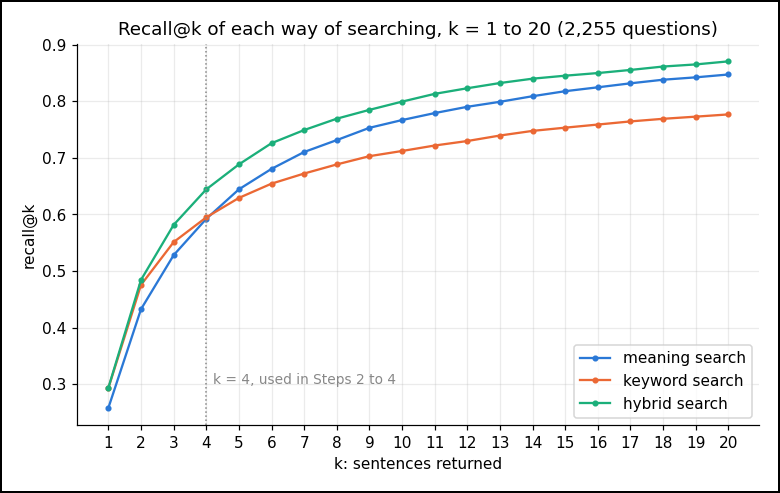

In [11]:
K_RANGE = range(1, 21)
by_k = pd.DataFrame({s: [results.loc[results["search"] == s, "ranks"].map(lambda r: recall_at(r, k)).mean()
                         for k in K_RANGE] for s in SEARCHES}, index=K_RANGE)
table = by_k.reset_index()
table.columns = ["k"] + [f"recall@k, {s}" for s in SEARCHES]
for s in SEARCHES:
    table[f"recall@k, {s}"] = table[f"recall@k, {s}"].map(lambda v: f"{v:.3f}")
print(f"Recall@k of each way of searching, {len(graded):,} questions:")
print()
show(table)

colors = {"meaning": common.BLUE, "keyword": common.ORANGE, "hybrid": common.AQUA}
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in SEARCHES:
    ax.plot(by_k.index, by_k[s], marker="o", markersize=3, color=colors[s], label=f"{s} search")
ax.axvline(TOP_K, color=common.GREY, linestyle=":", linewidth=1)
ax.text(TOP_K + 0.2, 0.3, "k = 4, used in Steps 2 to 4", color=common.GREY, fontsize=9)
ax.set_xticks(list(K_RANGE))
ax.set_xlabel("k: sentences returned")
ax.set_ylabel("recall@k")
ax.set_title(f"Recall@k of each way of searching, k = 1 to 20 ({len(graded):,} questions)")
ax.legend(loc="lower right")
plt.show()

**Observation:** hybrid search has the highest recall at every k from 2 to 20, and at k = 1 it is level with keyword search, 0.294 against 0.293.

**Observation:** keyword search is ahead of meaning search for k from 1 to 3, level with it at k = 4 (Step 4), and behind it from k = 5 on: at k = 20, keyword search's recall is 0.777 and meaning search's 0.847. These gaps at k other than 4 are not tested with intervals. That the switch falls right after k = 4, the k used in Steps 2 to 4, is a coincidence of this data: k = 4 was chosen from the number of listed sentences, not from this chart.

**Hypothesis:** a listed sentence that uses other words than the question gets a low BM25 score and lands far down keyword search's ranking, while meaning search still ranks it fairly high. A larger k reaches such sentences in meaning search's ranking, but not in keyword search's.

The gap between meaning search's recall@k and keyword search's cannot keep growing. At k = 981, every search returns all 981 sentences, so both recalls are 1 and the gap is exactly 0. The chart below shows the gap for k from 1 to 900.

Largest gap = 0.079, at k = 36
Gap at k = 900 = 0.006
Gap at k = 981 = 0.000


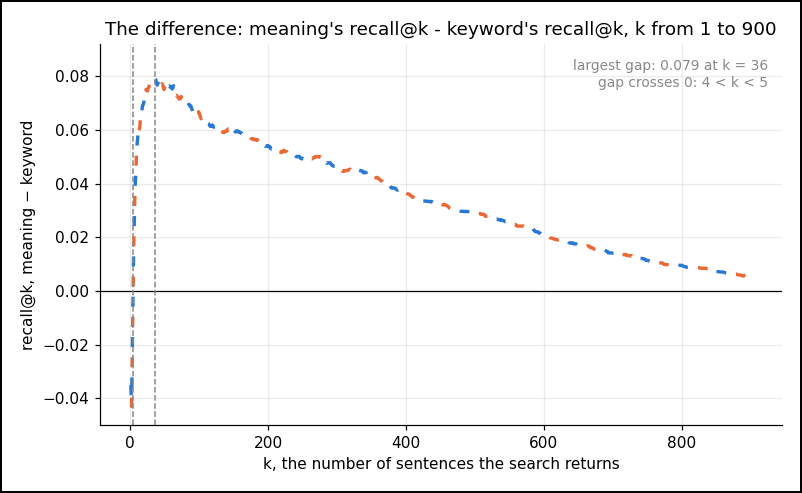

In [12]:
ALL_K = range(1, len(sentences) + 1)
recall_by_k = {s: [results.loc[results["search"] == s, "ranks"].map(lambda r: recall_at(r, k)).mean() for k in ALL_K]
               for s in ["meaning", "keyword"]}
gap = pd.Series(recall_by_k["meaning"], index=ALL_K) - pd.Series(recall_by_k["keyword"], index=ALL_K)
peak = gap.idxmax()
cross = gap[gap > 0].index[0]
print(f"Largest gap = {gap[peak]:.3f}, at k = {peak}")
print(f"Gap at k = 900 = {gap[900]:.3f}")
print(f"Gap at k = {len(sentences)} = {abs(gap[len(sentences)]):.3f}")

shown = gap.loc[:900]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(shown.index, shown, color="white", linewidth=2.2)
ax.plot(shown.index, shown, color=common.BLUE, linewidth=2.2, linestyle=(0, (3, 9)))
ax.plot(shown.index, shown, color=common.ORANGE, linewidth=2.2, linestyle=(6, (3, 9)))
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(TOP_K, color=common.GREY, linestyle="--", linewidth=1)
ax.axvline(peak, color=common.GREY, linestyle="--", linewidth=1)
ax.text(0.98, 0.96, f"largest gap: {gap[peak]:.3f} at k = {peak}\ngap crosses 0: {cross - 1} < k < {cross}",
        transform=ax.transAxes, ha="right", va="top", color=common.GREY, fontsize=9)
ax.set_ylim(-0.05, 0.092)
ax.set_xlabel("k, the number of sentences the search returns")
ax.set_ylabel("recall@k, meaning − keyword")
ax.set_title("The difference: meaning's recall@k - keyword's recall@k, k from 1 to 900")
plt.show()

**Observation:** the gap is largest at k = 36, 0.079, and then shrinks slowly, to 0.006 at k = 900.

**Observation:** from k = 4 to k = 10, hybrid search's recall rises from 0.644 to 0.799, but the language model would then read 10 sentences instead of 4, and at least 6 of them would be unlisted, because no question lists more than 4.

**Conclusion:** hybrid search leads or is level at every top-k size, a larger top k finds more listed sentences at the cost of more sentences to read, and meaning search gains on keyword search as k grows.

## Step 6 of 6: the three kinds of questions (comparison, inference, temporal)

**Is the best way of searching the same for every kind of question?** An average over all questions can hide kinds of questions where another way does better.

The dataset labels each question with one of three kinds:
- **Comparison**: does one article's report agree with another's?
- **Inference**: which person or company is described, using facts from several articles? The question never names the answer.
- **Temporal**: did one report come before or after another, or did a report change between two dates?

**[in real life]** The grades of Steps 2 and 3 are calculated again within each kind of question, from the ranks kept in Step 1. One short example of each kind first:

In [13]:
for kind in ["comparison", "inference", "temporal"]:
    of_kind = [q for q in graded if KIND[questions["question_type"][q]] == kind]
    shortest = min(of_kind, key=lambda q: len(questions["query"][q]))
    print(f"{kind.capitalize()}: {questions['query'][shortest]}")
    print()

grades = results.groupby(["kind", "search"])[["recall@4", "MRR@4"]].mean()
table = pd.DataFrame({"kind": [k for k in ["comparison", "inference", "temporal"]],
                      "questions": [f"{results[(results['kind'] == k) & (results['search'] == 'hybrid')].shape[0]:,}"
                                    for k in ["comparison", "inference", "temporal"]]})
for g, label in [("recall@4", "recall@4"), ("MRR@4", "MRR@4")]:
    for s in SEARCHES:
        table[f"{label}: {s}"] = [f"{grades.loc[(k, s), g]:.3f}" for k in table["kind"]]
overall = results.groupby("search")[["recall@4", "MRR@4"]].mean()
table.loc[len(table)] = (["total", f"{len(graded):,}"]
                         + [f"{overall.loc[s, g]:.3f}" for g in ["recall@4", "MRR@4"] for s in SEARCHES])
print("Grades by kind of question:")
print()
show(table)

Comparison: Does the TechCrunch article report on layoffs at Starz, while the Engadget article discusses layoffs within the entire video game industry?

Inference: What team was eliminated from European competitions after a loss at Old Trafford, as reported by both 'The Independent - Sports' and 'Sporting News'?

Temporal: Did Engadget report a discount on the 13.6-inch MacBook Air before The Verge reported a discount on Samsung Galaxy Buds 2?

Grades by kind of question:

kind        questions  recall@4: meaning  recall@4: keyword  recall@4: hybrid  MRR@4: meaning  MRR@4: keyword  MRR@4: hybrid
comparison        856              0.700              0.702             0.739           0.822           0.836          0.853
inference         816              0.493              0.570             0.609           0.720           0.869          0.869
temporal          583              0.573              0.473             0.555           0.699           0.632          0.681
total           2,255 

**Observation:** on comparison questions, hybrid search has the highest recall@4 and MRR@4, as over all questions.

**Observation:** on inference questions, keyword search's recall@4 is above meaning search's, 0.570 against 0.493. On temporal questions it is the other way round, 0.473 against 0.573, and meaning search's recall@4 is also above hybrid search's, 0.573 against 0.555.

The table below tests the gaps within each kind, as in Step 4.

In [14]:
rows = []
for kind in ["comparison", "inference", "temporal"]:
    keep = results.loc[(results["kind"] == kind) & (results["search"] == "hybrid"), "question"]
    for grade in ["recall@4", "MRR@4"]:
        for a, b in [("hybrid", "keyword"), ("hybrid", "meaning"), ("keyword", "meaning")]:
            d = (grade_of[grade][a] - grade_of[grade][b]).loc[keep]
            se = d.std(ddof=1) / np.sqrt(len(d))
            low, high = interval(d)
            rows.append({"kind": kind, "questions": f"{len(d):,}", "grade": "recall@4" if grade == "recall@4" else "MRR@4",
                         "ways compared": f"{a} − {b}", "mean difference": minus(d.mean(), 4),
                         "standard deviation": f"{d.std(ddof=1):.4f}", "standard error": f"{se:.4f}", "95% interval": f"{minus(low, 4)} to {minus(high, 4)}",
                         "0 inside?": "yes" if low <= 0 <= high else "no", **doubled(d, se)})
print("Gaps between the ways, within each kind of question:")
print()
show(pd.DataFrame(rows))

Gaps between the ways, within each kind of question:

kind        questions  grade     ways compared      mean difference  standard deviation  standard error  95% interval        0 inside?  interval, half-width doubled  0 inside, doubled?
comparison        856  recall@4  hybrid − keyword            0.0378              0.2346          0.0080  0.0221 to 0.0535    no         0.0063 to 0.0692              no
comparison        856  recall@4  hybrid − meaning            0.0399              0.2371          0.0081  0.0240 to 0.0558    no         0.0082 to 0.0717              no
comparison        856  recall@4  keyword − meaning           0.0021              0.3216          0.0110  −0.0194 to 0.0237   yes        −0.0409 to 0.0452             yes
comparison        856  MRR@4     hybrid − keyword            0.0163              0.2313          0.0079  0.0008 to 0.0318    no         −0.0147 to 0.0472             yes
comparison        856  MRR@4     hybrid − meaning            0.0303              0.

**Observation:** on comparison questions, hybrid search beats both other ways on both grades, and the gaps are real by the standard rule. With doubled half-widths, hybrid search's recall@4 leads stay real, but its MRR@4 leads hold 0. Keyword search minus meaning search has 0 inside its interval on both grades.

**Observation:** on inference questions, keyword search beats meaning search on both grades, and the gaps are real. Hybrid search beats meaning search on both grades and keyword search on recall@4, and is level with keyword search on MRR@4.

**Observation:** on temporal questions, meaning search beats keyword search on both grades, and the gaps are real. Hybrid search minus meaning search has 0 inside its interval on both grades, so the data cannot tell those two apart on temporal questions.

Over all questions, keyword search and meaning search were level on recall@4, yet on inference and temporal questions they differ in opposite directions. The sum of the differences within each kind shows how much each kind adds to the overall difference, and the overall mean difference is that total divided by all the questions:

In [15]:
d = grade_of["recall@4"]["keyword"] - grade_of["recall@4"]["meaning"]
kind_of = results[results["search"] == "hybrid"].set_index("question")["kind"]
sums = d.groupby(kind_of).sum()
print("Sum of the differences, keyword recall@4 − meaning recall@4, by kind of question:")
for kind in ["comparison", "inference", "temporal"]:
    print(f"  {kind.capitalize()} = {minus(sums[kind], 2)}")
print(f"  All {len(d):,} questions = {d.sum():.2f} (adding the rounded numbers above gives {sum(round(v, 2) for v in sums):.2f})")
print(f"Mean difference over all questions = {d.sum():.2f} / {len(d):,} = {d.mean():.4f}")

Sum of the differences, keyword recall@4 − meaning recall@4, by kind of question:
  Comparison = 1.83
  Inference = 62.33
  Temporal = −58.17
  All 2,255 questions = 6.00 (adding the rounded numbers above gives 5.99)
Mean difference over all questions = 6.00 / 2,255 = 0.0027


**Observation:** over all questions, keyword search and meaning search were level on recall@4 because the inference and temporal questions' differences nearly cancel: their sums are 62.33 and (−58.17), and the comparison questions add 1.83, so the sum over all 2,255 questions is only 6.00.

The kinds may also differ in how many sentences they list, and recall@4 falls as the number listed rises: a question that lists 4 needs all 4 in the top 4 for a recall@4 of 1. If one way is better at finding a question's third and fourth listed sentences, it gains on a kind with many listed sentences per question. So the keyword-minus-meaning gap, which flips between inference and temporal questions, could come from the number of listed sentences, not from the kind itself. The table below compares the ways within each kind and each number of listed sentences.

In [16]:
by_listed = results.groupby(["kind", "listed", "search"])["recall@4"].agg(["mean", "size"]).reset_index()
table = by_listed.pivot_table(index=["kind", "listed"], columns="search", values="mean")[SEARCHES].reset_index()
table.insert(2, "questions", by_listed[by_listed["search"] == "hybrid"].set_index(["kind", "listed"])["size"].values)
table.columns = ["kind", "sentences listed", "questions"] + [f"recall@4: {s}" for s in SEARCHES]
table["sentences listed"] = table["sentences listed"].astype(str)
table["questions"] = table["questions"].map(lambda v: f"{v:,}")
for s in SEARCHES:
    table[f"recall@4: {s}"] = table[f"recall@4: {s}"].map(lambda v: f"{v:.3f}")
table.loc[len(table)] = (["total", "", f"{len(graded):,}"]
                         + [f"{results.loc[results['search'] == s, 'recall@4'].mean():.3f}" for s in SEARCHES])
print("Recall@4 by kind of question and number of sentences listed:")
print()
show(table)

Recall@4 by kind of question and number of sentences listed:

kind        sentences listed  questions  recall@4: meaning  recall@4: keyword  recall@4: hybrid
comparison                 2        658              0.745              0.739             0.783
comparison                 3        198              0.547              0.579             0.596
inference                  2        103              0.680              0.767             0.772
inference                  3        315              0.509              0.618             0.650
inference                  4        398              0.433              0.481             0.534
temporal                   2        318              0.679              0.593             0.676
temporal                   3        265              0.445              0.330             0.409
total                             2,255              0.592              0.595             0.644


**Observation:** within each number of listed sentences, the order holds: keyword search's recall@4 is above meaning search's in every inference row, and below it in every temporal row. These gaps within single rows are not tested with intervals, and the smallest row has 103 questions. Still, the order is the same in all five rows, so the number of listed sentences does not explain the gaps between the kinds.

Why would keyword search do worse on temporal questions? Keyword search scores only the words a question shares with a sentence. The table below gives, for each kind, how many of a question's distinct words (each word counted once) appear in at least one of its listed sentences, as a share of the question's distinct words, averaged over the questions. Every word counts, including "the", "did" and "before".

In [17]:
rows = []
all_shares = []
for kind in ["comparison", "inference", "temporal"]:
    shares = []
    for q in graded:
        if KIND[questions["question_type"][q]] != kind:
            continue
        question_words = set(words_of(questions["query"][q]))
        listed_words = set().union(*[set(words_of(s)) for s in listed.loc[listed["question"] == q, "sentence"]])
        shares.append(len(question_words & listed_words) / len(question_words))
    rows.append({"kind": kind, "questions": f"{len(shares):,}",
                 "question's words in its listed sentences: average": f"{np.mean(shares):.1%}"})
    all_shares += shares
rows.append({"kind": "total", "questions": f"{len(all_shares):,}",
             "question's words in its listed sentences: average": f"{np.mean(all_shares):.1%}"})
print("How many of a question's words its listed sentences contain:")
print()
show(pd.DataFrame(rows))

How many of a question's words its listed sentences contain:

kind        questions  question's words in its listed sentences: average
comparison        856                                              37.1%
inference         816                                              41.9%
temporal          583                                              32.1%
total           2,255                                              37.5%


**Observation:** temporal questions share the fewest of their words with their listed sentences, 32.1%, and inference questions the most, 41.9%: the same order as keyword search's recall@4 minus meaning search's, which is lowest on temporal questions, (−0.0998), highest on inference questions, 0.0764, and in between on comparison questions, 0.0021, whose share of words, 37.1%, is also in between.

**Hypothesis:** with fewer of its words in its listed sentences, a temporal question gives keyword search fewer words to match, while meaning search still matches the topic. Which of a temporal question's words are missing from its listed sentences is not checked here, and three kinds of questions show a matching order, not a cause.

**Conclusion:** the best way of searching is not the same for every kind of question: keyword search beats meaning search on inference questions, meaning search beats keyword search on temporal questions (on comparison questions the two are level: 0 is inside both intervals), and hybrid search is best or level with the best on every kind.

## Key takeaways

- Recall@k counts how many of a question's listed sentences the top k holds. MRR@k says how high the first listed sentence ranks. A search can do better on one grade and worse on the other: on the example question in Steps 2 and 3, meaning search had the better MRR@4 and keyword search the better recall@4.
- Comparing two searches question by question, with a 95% interval of the mean difference, shows whether a gap is larger than another set of test questions could make.
- Over all the test questions, hybrid search led on both grades. Its lead in listed sentences found was larger than chance even with doubled intervals.
- Keyword search and meaning search found about as many listed sentences overall, but on different kinds of questions: keyword search did better on inference questions, meaning search on temporal questions.
- A larger top k finds more listed sentences, but gives the language model more sentences to read.
- The collection held only listed sentences, so a real search over every sentence of the articles would get lower grades.

## Conclusion

On these test questions, whose collection holds only listed sentences, the live search should use hybrid search: it finds the most listed sentences, and on no kind of question does another way beat it by more than chance.